# Portafolio Cuantitativo Neutral al Mercado

## Extensión: Amplitud — Muchas Canastas, Selección Dentro de Cada Ventana

**Autor:** Samuel

**Institución:** Tec de Monterrey

**Área:** Finanzas Cuantitativas, Economía Estadística y Machine Learning

**Notebooks previos:** `Backtest-Corregido.ipynb` (contabilidad corregida), `Beta-Anclado-OU.ipynb` y `Remuestreo-Costos.ipynb` (reducción de rotación y costos)

---

Este notebook parte de la conclusión de los anteriores: con contabilidad corregida, la canasta USDCAD/USDNOK/USDSEK/USDSGD tiene una señal bruta significativa pero pequeña (~2% anual) que los costos consumen, y reducir la rotación, remuestrear a 4h/8h o afinar umbrales no cambió el neto (≈ 0). El límite no está en el ajuste sino en el número de apuestas independientes (~20 operaciones por configuración).

**Pregunta:** ¿un borde pequeño repetido en muchas canastas poco correlacionadas puede producir un neto positivo? La selección de canastas se hace **dentro de cada ventana de walk-forward y solo con datos de entrenamiento**, y todo el proceso se valida con placebo.

## Estructura de este Notebook

1. **Instalación de librerías** — las mismas de los notebooks previos (`numba` muy recomendado aquí).
2. **Fase 1: Datos** — *ampliada*. 18 divisas con verificación de nivel de precio y cobertura.
3. **Fase 2: Canastas candidatas y dependencia del universo** — *nueva*. 4,029 canastas; el universo tiene ~13 residuos independientes tras quitar 1 a 3 factores.
4. **Fase 3: Motor por spread** — *reutilizada* de `Beta-Anclado-OU.ipynb`, generalizada: recibe cualquier vector de pesos sobre log-precios. Es el mismo motor para las dos rutas.
5. **Fase 4: Ruta B — residuos de factores** — *nueva*. Cada divisa menos sus primeros k factores, como un spread con pesos congelados por ventana (Avellaneda y Lee, 2010).
6. **Fase 5: Ruta A — canastas cointegradas** — *nueva*. Prefiltro + cointegración con corrección FDR dentro de cada ventana, mismo motor.
7. **Fase 6: Comparación A vs. B y placebo** — misma ventana, mismos costos; número de apuestas independientes y neto.
8. **Conclusión**.

## Instalación de Librerías

Mismas librerías de `K-D.ipynb` y `Beta-Anclado-OU.ipynb`. `numba` es opcional pero acelera mucho la máquina de estados.

In [ ]:
# Fase 1 — Datos
# %pip install yfinance pandas numpy

# Fase 3 — Cointegración y corrección por pruebas múltiples
# %pip install scipy statsmodels

# Fase 4 — Motor (opcional, acelera ~50x)
# %pip install numba

## Fase 1: Datos

Mismo universo base que `main.ipynb`, ampliado con divisas de otros bloques económicos. Dos cambios frente a los notebooks previos: (1) se renombra por **ticker** y no por posición (lección de `Backtest-Corregido.ipynb`: yfinance devuelve las columnas en orden alfabético), y (2) las divisas nuevas se aceptan solo si tienen cobertura horaria suficiente, porque no todas la tienen en Yahoo.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

In [2]:
pd.set_option('display.max_columns', None)

base = ['EURUSD','GBPUSD','AUDUSD','NZDUSD','USDJPY','USDCAD',
        'USDCHF','USDMXN','USDCNY','USDSEK','USDNOK','USDSGD']
nuevas = ['USDZAR','USDBRL','USDINR','USDKRW','USDPLN','USDHUF','USDCZK','USDILS','USDTHB']

tickers = {k: f'{k}=X' for k in base + nuevas}

raw_close = yf.download(list(tickers.values()), period='729d', interval='60m', progress=False)['Close']
ticker_to_name = {v: k for k, v in tickers.items()}
raw_data = raw_close.rename(columns=ticker_to_name)

print(f"Descargado: {raw_data.shape}")

Descargado: (17423, 21)


In [4]:
# Cobertura: fracción de barras horarias con dato, respecto a la divisa con más datos
cobertura = raw_data.notna().mean() / raw_data.notna().mean().max()
print(cobertura.sort_values().round(3))

MIN_COBERTURA = 0.90
aceptadas = cobertura[cobertura >= MIN_COBERTURA].index.tolist()
descartadas = [c for c in tickers if c not in aceptadas]
print(f"\nAceptadas ({len(aceptadas)}): {aceptadas}")
print(f"Descartadas por cobertura ({len(descartadas)}): {descartadas}")

Ticker
USDBRL    0.680
USDCNY    0.771
USDINR    0.818
USDKRW    0.951
USDILS    0.964
USDSEK    0.977
USDTHB    0.985
USDNOK    0.989
USDJPY    0.989
USDCHF    0.991
USDSGD    0.994
EURUSD    0.994
GBPUSD    0.994
USDMXN    0.995
USDZAR    0.998
AUDUSD    0.998
NZDUSD    0.998
USDPLN    0.998
USDCAD    0.998
USDHUF    1.000
USDCZK    1.000
dtype: float64

Aceptadas (18): ['AUDUSD', 'EURUSD', 'GBPUSD', 'NZDUSD', 'USDCAD', 'USDCHF', 'USDCZK', 'USDHUF', 'USDILS', 'USDJPY', 'USDKRW', 'USDMXN', 'USDNOK', 'USDPLN', 'USDSEK', 'USDSGD', 'USDTHB', 'USDZAR']
Descartadas por cobertura (3): ['USDCNY', 'USDBRL', 'USDINR']


In [5]:
data = raw_data[aceptadas].ffill().dropna()

# Rangos aproximados — ajústalos si alguna divisa queda fuera por una razón legítima
expected = {'EURUSD':(0.9,1.4),'GBPUSD':(1.0,1.6),'AUDUSD':(0.5,0.9),'NZDUSD':(0.5,0.8),
            'USDJPY':(100,175),'USDCAD':(1.1,1.6),'USDCHF':(0.7,1.1),'USDMXN':(14,26),
            'USDCNY':(6.3,7.6),'USDSEK':(8,12),'USDNOK':(8,12.5),'USDSGD':(1.1,1.6),
            'USDZAR':(12,24),'USDBRL':(4,7),'USDINR':(75,100),'USDKRW':(1100,1700),
            'USDPLN':(3.3,4.8),'USDHUF':(280,430),'USDCZK':(19,27),'USDILS':(3,4.3),'USDTHB':(28,42)}

chk = pd.DataFrame({'media': data.mean(), 'min': data.min(), 'max': data.max()})
chk['ok'] = [expected[c][0] <= chk.loc[c, 'media'] <= expected[c][1] for c in chk.index]
display(chk.round(4))
print(data.shape, data.index.min(), '->', data.index.max())
assert chk['ok'].all(), "Algún nivel de precio no corresponde a su nombre (o el rango esperado hay que ajustarlo)"

,media,min,max,ok
Ticker,,,,
AUDUSD,0.6671,0.5952,0.7273,True
EURUSD,1.1215,1.0196,1.2047,True
GBPUSD,1.3117,1.2108,1.3850,True
NZDUSD,0.5905,0.5512,0.6376,True
USDCAD,1.3853,1.3344,1.4781,True
USDCHF,0.8391,0.7609,0.9222,True
USDCZK,22.0917,20.1080,24.7250,True
USDHUF,347.3329,300.1800,406.1000,True
USDILS,3.4164,2.7993,3.8435,True


(17423, 18) 2024-01-09 00:00:00+00:00 -> 2026-10-23 19:00:00+01:00


In [6]:
nombres = {
    'EURUSD': 'Euro',        'GBPUSD': 'Libra',       'AUDUSD': 'Dolar_AUS',   'NZDUSD': 'Dolar_NZ',
    'USDCAD': 'Dolar_CAN',   'USDCHF': 'Franco_SUI',  'USDCZK': 'Corona_CZ',   'USDHUF': 'Forinto_HU',
    'USDILS': 'Shekel_IL',   'USDJPY': 'Yen',         'USDKRW': 'Won_KR',      'USDMXN': 'Peso_MX',
    'USDNOK': 'Corona_NO',   'USDPLN': 'Zloty_PL',    'USDSEK': 'Corona_SE',   'USDSGD': 'Dolar_SG',
    'USDTHB': 'Baht_TH',     'USDZAR': 'Rand_ZA',
}
# Documenta la dirección de cada cotización (no cambia los datos)
cotizacion = {nombres[t]: ('USD por unidad' if t.endswith('USD') else 'unidades por USD') for t in nombres}

data_t = data.copy()          # versión con tickers, por si hay que compararla con los notebooks previos
data = data_t.rename(columns=nombres)
print(pd.Series(cotizacion))

Euro            USD por unidad
Libra           USD por unidad
Dolar_AUS       USD por unidad
Dolar_NZ        USD por unidad
Dolar_CAN     unidades por USD
Franco_SUI    unidades por USD
Corona_CZ     unidades por USD
Forinto_HU    unidades por USD
Shekel_IL     unidades por USD
Yen           unidades por USD
Won_KR        unidades por USD
Peso_MX       unidades por USD
Corona_NO     unidades por USD
Zloty_PL      unidades por USD
Corona_SE     unidades por USD
Dolar_SG      unidades por USD
Baht_TH       unidades por USD
Rand_ZA       unidades por USD
dtype: str


## Fase 2: Canastas Candidatas y Dependencia del Universo

Se enumeran todas las canastas de 2 a 4 activos. Ninguna se da por válida: es el espacio de búsqueda, y cada ventana de walk-forward elegirá entre ellas solo con su entrenamiento. Antes de seleccionar, se mide cuánta independencia real hay en el universo: si casi todas las divisas se mueven con un solo factor (el dólar), las canastas serán muchas pero las apuestas independientes, pocas.

In [7]:
from itertools import combinations

assets = list(data.columns)
baskets = [c for k in (2, 3, 4) for c in combinations(assets, k)]
conteo = {k: sum(len(b) == k for b in baskets) for k in (2, 3, 4)}
print(f"{len(baskets)} canastas candidatas | por tamaño: {conteo}")

4029 canastas candidatas | por tamaño: {2: 153, 3: 816, 4: 3060}


Varianza explicada por el 1er factor: 55.1%
Varianza explicada por los 3 primeros: 67.4%
Número efectivo de factores independientes: 3.1 (de 18 divisas)


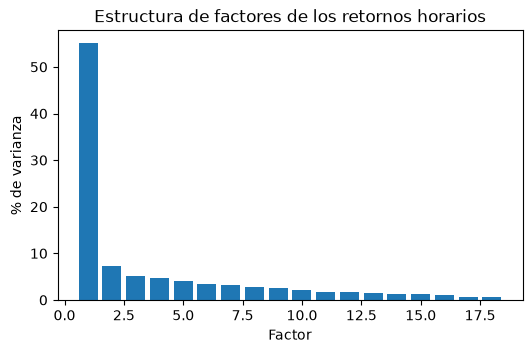

In [8]:
ret = np.log(data).diff().dropna()
corr = ret.corr()

eig = np.linalg.eigvalsh(corr.values)[::-1]          # autovalores de mayor a menor
var_exp = eig / eig.sum()
n_efectivo = eig.sum()**2 / (eig**2).sum()            # "número efectivo" de factores independientes

print(f"Varianza explicada por el 1er factor: {var_exp[0]*100:.1f}%")
print(f"Varianza explicada por los 3 primeros: {var_exp[:3].sum()*100:.1f}%")
print(f"Número efectivo de factores independientes: {n_efectivo:.1f} (de {len(assets)} divisas)")

plt.figure(figsize=(6, 3.5))
plt.bar(range(1, len(eig) + 1), var_exp * 100)
plt.xlabel("Factor"); plt.ylabel("% de varianza")
plt.title("Estructura de factores de los retornos horarios")
plt.show()

### Independencia de los residuos

El número efectivo de factores de los retornos (3.1) mide cuántas apuestas direccionales independientes hay. Una canasta market-neutral cancela el factor común, así que lo relevante es la independencia de lo que **queda después de quitar los primeros k factores**. Se mide para k = 0, 1, 2, 3, 4.

In [9]:
def n_efectivo_residual(retornos, k):
    X = ((retornos - retornos.mean()) / retornos.std()).values
    U, S, Vt = np.linalg.svd(X, full_matrices=False)
    residuo = X - (U[:, :k] * S[:k]) @ Vt[:k] if k > 0 else X
    eigs = np.linalg.eigvalsh(np.corrcoef(residuo.T))
    return eigs.sum()**2 / (eigs**2).sum()

for k in range(0, 5):
    print(f"k = {k} factores removidos -> número efectivo de residuos independientes: {n_efectivo_residual(ret, k):.1f}")

k = 0 factores removidos -> número efectivo de residuos independientes: 3.1
k = 1 factores removidos -> número efectivo de residuos independientes: 12.6
k = 2 factores removidos -> número efectivo de residuos independientes: 13.0
k = 3 factores removidos -> número efectivo de residuos independientes: 12.4
k = 4 factores removidos -> número efectivo de residuos independientes: 11.7


## Fase 3: Motor por Spread

Mismo motor de `Beta-Anclado-OU.ipynb` (β anclado + umbrales OU con costo + abstención), generalizado: un spread es cualquier combinación `s = log-precios @ w` con pesos `w` congelados en la ventana de prueba. El retorno se normaliza por la exposición bruta `Σ|w|` (en unidades de log-precio) y el costo es 1 pb por pata por lado, de modo que una canasta de 4 activos y un residuo con 18 patas son comparables.

In [10]:
from scipy import stats
from scipy.signal import lfilter
try:
    from numba import njit
except ImportError:
    njit = lambda f: f      # sin numba funciona, pero MUY lento en las Fases 4-6

TEST_DAYS, TRAIN_DAYS, MIN_TRAIN = 30, 120, 240
STOP, HL_MAX = 3.5, 24 * 15      # stop en sigmas; vida media máxima aceptada (barras horarias)
COST_BPS = 1.0

In [11]:
def fit_ou(s):
    x, y = s[:-1], s[1:]
    b, a = np.polyfit(x, y, 1)
    if not (0.0 < b < 1.0):
        return None
    r = y - (a + b * x)
    return dict(b=b, mu=a / (1 - b), sig=r.std(ddof=2) / np.sqrt(1 - b * b), hl=np.log(2) / (-np.log(b)))

@njit
def positions_from_z(z, k, e, stop):
    n = len(z); pos = np.zeros(n); p = 0.0; blocked = 0.0
    for t in range(n):
        zt = z[t]
        if blocked != 0.0 and abs(zt) < k:
            blocked = 0.0
        if p == 0.0:
            if blocked == 0.0:
                if zt >= k: p = -1.0
                elif zt <= -k: p = 1.0
        else:
            if p < 0 and zt <= e: p = 0.0
            elif p > 0 and zt >= -e: p = 0.0
            elif abs(zt) >= stop:
                blocked = 1.0 if zt > 0 else -1.0
                p = 0.0
        pos[t] = p
    return pos

In [12]:
def ou_band_search(b, c_side_z, n=40000, seed=0, ks=np.arange(0.75, 3.01, 0.25), es=(0.0, 0.25, 0.5, 1.0)):
    eps = np.random.default_rng(seed).standard_normal(n) * np.sqrt(1 - b * b)
    z = lfilter([1.0], [1.0, -b], eps); dz = np.diff(z); best = None
    for k in ks:
        for e in es:
            if e >= k: continue
            pos = positions_from_z(z, k, e, STOP)
            rate = ((pos[:-1] * dz).sum() - c_side_z * np.abs(np.diff(pos, prepend=0.0)).sum()) / n
            if best is None or rate > best[2]:
                best = (k, e, rate)
    return best if best and best[2] > 0 else None      # None = abstenerse

def run_spread(Lp_tr, Lp_te, w, cost_bps=COST_BPS, mode='ou', fixed_ke=(2.0, 0.5), seed=0):
    """Opera un spread s = log-precios @ w con pesos congelados. None si se abstiene."""
    s_tr, s_te = Lp_tr @ w, Lp_te @ w
    ou = fit_ou(s_tr)
    if ou is None or ou['hl'] > HL_MAX:
        return None
    E = np.abs(w).sum()                                    # exposición bruta
    if mode == 'fixed':
        k, e = fixed_ke
    else:
        res = ou_band_search(ou['b'], (cost_bps / 1e4) * E / ou['sig'], seed=seed)
        if res is None:
            return None
        k, e = res[0], res[1]
    pos = positions_from_z((s_te - ou['mu']) / ou['sig'], k, e, STOP)
    gross = (pos[:-1] * np.diff(s_te)).sum()
    cost = np.abs(np.diff(pos, prepend=0.0)).sum() * E * cost_bps / 1e4
    ops = int(((pos[1:] != 0) & (pos[:-1] == 0)).sum() + (pos[0] != 0))
    return dict(gross=gross / E, cost=cost / E, net=(gross - cost) / E, ops=ops, k=k, e=e, hl=ou['hl'])

## Fase 4: Ruta B — Residuos de Factores

Idea (Avellaneda y Lee, 2010): los primeros k factores de los retornos (el primero es el dólar) mueven casi todo a la vez. Lo que queda de cada divisa **después de quitarlos** es un residuo que puede revertir a su media. Con la proyección ortogonal `M = I − V Vᵀ` (V = k primeros autovectores de la correlación del entrenamiento), el residuo de la divisa i es la columna i de `M`, y como cada residuo es una combinación lineal de log-precios, entra directo al motor de la Fase 3 con pesos congelados. Son 18 spreads (uno por divisa), sin enumerar canastas ni correr pruebas de cointegración.

In [13]:
def pesos_residuo(R_train, k):
    """Columna i = pesos (sobre log-precios) del residuo de la divisa i tras quitar los k primeros factores."""
    sd = R_train.std(0)
    Z = (R_train - R_train.mean(0)) / sd
    vals, vecs = np.linalg.eigh(np.corrcoef(Z.T))
    V = vecs[:, ::-1][:, :k]                       # k autovectores con mayor autovalor
    M = np.eye(R_train.shape[1]) - V @ V.T
    return M / sd[:, None]

def ventanas(index, train_days=TRAIN_DAYS):
    day = index.normalize().values; ud = np.unique(day)
    for j in range(MIN_TRAIN, len(ud) - TEST_DAYS + 1, TEST_DAYS):
        tr = (day >= ud[j - train_days]) & (day < ud[j])
        te = (day >= ud[j]) & (day < ud[j + TEST_DAYS])
        yield j, tr, te

In [14]:
def run_ruta_B(data, k=2, mode='ou', cost_bps=COST_BPS, train_days=TRAIN_DAYS, seed=0):
    Lp = np.log(data).values
    R = np.diff(Lp, axis=0, prepend=Lp[:1])
    rows = []
    for j, tr, te in ventanas(data.index, train_days):
        W = pesos_residuo(R[tr], k)                  # pesos calibrados SOLO con el entrenamiento
        res = [run_spread(Lp[tr], Lp[te], W[:, i], cost_bps, mode, seed=seed) for i in range(W.shape[1])]
        ok = [r for r in res if r is not None]
        n_tot = W.shape[1]
        rows.append(dict(window=j, gross=sum(r['gross'] for r in ok) / n_tot,
                         cost=sum(r['cost'] for r in ok) / n_tot, net=sum(r['net'] for r in ok) / n_tot,
                         ops=sum(r['ops'] for r in ok), n_spreads=len(ok), n_tot=n_tot))
    return pd.DataFrame(rows)

def summarize(res, label):
    g, n = res.gross, res.net
    be = g.mean() / res.cost.mean() if res.cost.mean() > 0 else np.nan
    return pd.Series({'bruto': g.mean(), 'p_bruto': stats.ttest_1samp(g, 0).pvalue,
                      'neto': n.mean(), 'p_neto': stats.ttest_1samp(n, 0).pvalue,
                      'neto>0': f"{(n > 0).sum()}/{len(n)}", 'spreads/vent': res.n_spreads.mean(),
                      'ops/vent': res.ops.mean(), 'break-even (x costo)': be}, name=label)

In [15]:
rows = []
for k in (1, 2, 3):
    for mode in ('fixed', 'ou'):
        rows.append(summarize(run_ruta_B(data, k=k, mode=mode), f'B_k{k}_{mode}'))
tabla_B = pd.DataFrame(rows)
display(tabla_B)

,bruto,p_bruto,neto,p_neto,neto>0,spreads/vent,ops/vent,break-even (x costo)
B_k1_fixed,-0.000317,0.313115,-0.000390,0.226729,5/16,11.750,8.4375,-4.342791
B_k1_ou,-0.000117,0.827535,-0.000282,0.598876,5/16,11.750,18.5625,-0.707446
B_k2_fixed,-0.000166,0.413755,-0.000242,0.246816,4/16,12.375,8.8750,-2.166912
B_k2_ou,0.000259,0.598581,0.000068,0.886867,7/16,12.375,21.0000,1.357731
B_k3_fixed,-0.000398,0.067880,-0.000485,0.033963,5/16,13.250,9.8750,-4.603973
B_k3_ou,-0.000096,0.776284,-0.000306,0.359004,6/16,13.250,22.9375,-0.455635


### Diagnóstico: ¿persiste la reversión de los residuos?

Para cada ventana se mide la fuerza de reversión (1 − b, con b la autocorrelación a 1 hora del residuo) de los 18 spreads en entrenamiento y en prueba, y se calcula la correlación de rangos (Spearman) entre ambas. Una reversión genuina persiste: la correlación media debe ser positiva y significativa. Con ruido, ≈ 0.

In [16]:
def persistencia_B(data, k=2):
    Lp = np.log(data).values
    R = np.diff(Lp, axis=0, prepend=Lp[:1])
    rows = []
    for j, tr, te in ventanas(data.index):
        W = pesos_residuo(R[tr], k)
        r_tr, r_te = [], []
        for i in range(W.shape[1]):
            s_tr, s_te = Lp[tr] @ W[:, i], Lp[te] @ W[:, i]
            r_tr.append(1 - np.polyfit(s_tr[:-1], s_tr[1:], 1)[0])    # reversión en entrenamiento
            r_te.append(1 - np.polyfit(s_te[:-1], s_te[1:], 1)[0])    # reversión en prueba
        rows.append(dict(window=j, rho=stats.spearmanr(r_tr, r_te).statistic))
    return pd.DataFrame(rows)

for k in (1, 2, 3):
    p = persistencia_B(data, k)
    print(f"k={k}: correlación media entrenamiento-prueba = {p.rho.mean():.3f} "
          f"(p = {stats.ttest_1samp(p.rho, 0).pvalue:.3f}, {(p.rho > 0).sum()}/{len(p)} ventanas positivas)")

k=1: correlación media entrenamiento-prueba = -0.007 (p = 0.885, 9/16 ventanas positivas)
k=2: correlación media entrenamiento-prueba = 0.032 (p = 0.376, 9/16 ventanas positivas)
k=3: correlación media entrenamiento-prueba = 0.058 (p = 0.262, 11/16 ventanas positivas)


### Diagnóstico: ¿la cointegración detectada en entrenamiento persiste en prueba?

Es la suposición central de la Ruta A. Para cada ventana y cada canasta candidata se calcula en entrenamiento un puntaje de cointegración (estadístico tipo Engle-Granger sobre el residuo de la regresión de un activo contra los demás). Con los pesos congelados se mide la fuerza de reversión del mismo spread en prueba. Se reporta (1) la correlación de rangos entre ambos y (2) la reversión media en prueba del 5% de canastas con mejor puntaje contra la media de todas. Si la cointegración persiste, (1) > 0 y (2) supera a la media.

In [17]:
from itertools import combinations

def _df(s):
    sl = s[:-1] - s[:-1].mean(); ds = np.diff(s)
    d = (sl @ ds) / (sl @ sl)                       # coeficiente de Δs sobre s_{t-1}: negativo = reversión
    e = ds - d * sl
    t = d / np.sqrt(e.var(ddof=2) / (sl @ sl))
    return -d, -t                                   # (fuerza de reversión, estadístico: mayor = más reversión)

def persistencia_A(data, tam=(2, 3, 4), top=0.05):
    Lp = np.log(data).values
    cestas = [c for k in tam for c in combinations(range(data.shape[1]), k)]
    rows = []
    for j, tr, te in ventanas(data.index):
        Ltr, Lte = Lp[tr], Lp[te]
        sc, dte = np.empty(len(cestas)), np.empty(len(cestas))
        for n, idx in enumerate(cestas):
            A = np.column_stack([np.ones(len(Ltr))] + [Ltr[:, m] for m in idx[1:]])
            coef = np.linalg.lstsq(A, Ltr[:, idx[0]], rcond=None)[0]
            sc[n] = _df(Ltr[:, idx[0]] - A @ coef)[1]                      # puntaje en entrenamiento
            s_te = Lte[:, idx[0]] - Lte[:, list(idx[1:])] @ coef[1:]       # pesos congelados
            dte[n] = _df(s_te)[0]                                           # reversión en prueba
        sel = np.argsort(-sc)[:max(1, int(len(cestas) * top))]
        rows.append(dict(window=j, rho=stats.spearmanr(sc, dte).statistic,
                         top=dte[sel].mean(), todas=dte.mean()))
    return pd.DataFrame(rows)

pA = persistencia_A(data)
print(f"Correlación media puntaje(entrenamiento)-reversión(prueba) = {pA.rho.mean():.3f} "
      f"(p = {stats.ttest_1samp(pA.rho, 0).pvalue:.3f}, {(pA.rho > 0).sum()}/{len(pA)} ventanas positivas)")
print(f"Reversión media en prueba: top 5% = {pA.top.mean():.5f} vs. todas = {pA.todas.mean():.5f} "
      f"(diferencia p = {stats.ttest_rel(pA.top, pA.todas).pvalue:.3f})")

Correlación media puntaje(entrenamiento)-reversión(prueba) = 0.153 (p = 0.000, 13/16 ventanas positivas)
Reversión media en prueba: top 5% = 0.01712 vs. todas = 0.01215 (diferencia p = 0.001)
